In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/student-mat.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [3]:
df.shape

(395, 33)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [5]:
missing = df.isna().sum()
missing

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [6]:
duplicates = df.duplicated().sum()
duplicates

np.int64(0)

In [7]:
bad_school = len(df) - df["school"].isin(["GP", "MS"]).sum()
bad_age = len(df) - df["age"].between(15, 22).sum()
bad_study = len(df) - df["studytime"].isin([1, 2, 3, 4]).sum()

In [8]:
bad_absences = len(df) - df["absences"].between(0, 93).sum()
bad_g1 = len(df) - df["G1"].between(0, 20).sum()
bad_g2 = len(df) - df["G2"].between(0, 20).sum()
bad_g3 = len(df) - df["G3"].between(0, 20).sum()
bad_grades = bad_g1 + bad_g2 + bad_g3

In [9]:
quality = pd.DataFrame()
quality["check"] = ["Missing cells","Repeated rows","Invalid school codes","Invalid ages","Invalid study codes","Invalid absence counts","Invalid grades"]

In [10]:
quality["count"] = [missing.sum(), duplicates, bad_school, bad_age,bad_study, bad_absences, bad_grades]
quality

,check,count
0,Missing cells,0
1,Repeated rows,0
2,Invalid school codes,0
3,Invalid ages,0
4,Invalid study codes,0
5,Invalid absence counts,0
6,Invalid grades,0


In [11]:
summary = df[["absences", "G1", "G2", "G3"]].describe()
summary

,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000
mean,5.708861,10.908861,10.713924,10.415190
std,8.003096,3.319195,3.761505,4.581443
min,0.000000,3.000000,0.000000,0.000000
25%,0.000000,8.000000,9.000000,8.000000
50%,4.000000,11.000000,11.000000,11.000000
75%,8.000000,13.000000,13.000000,14.000000
max,75.000000,19.000000,19.000000,20.000000


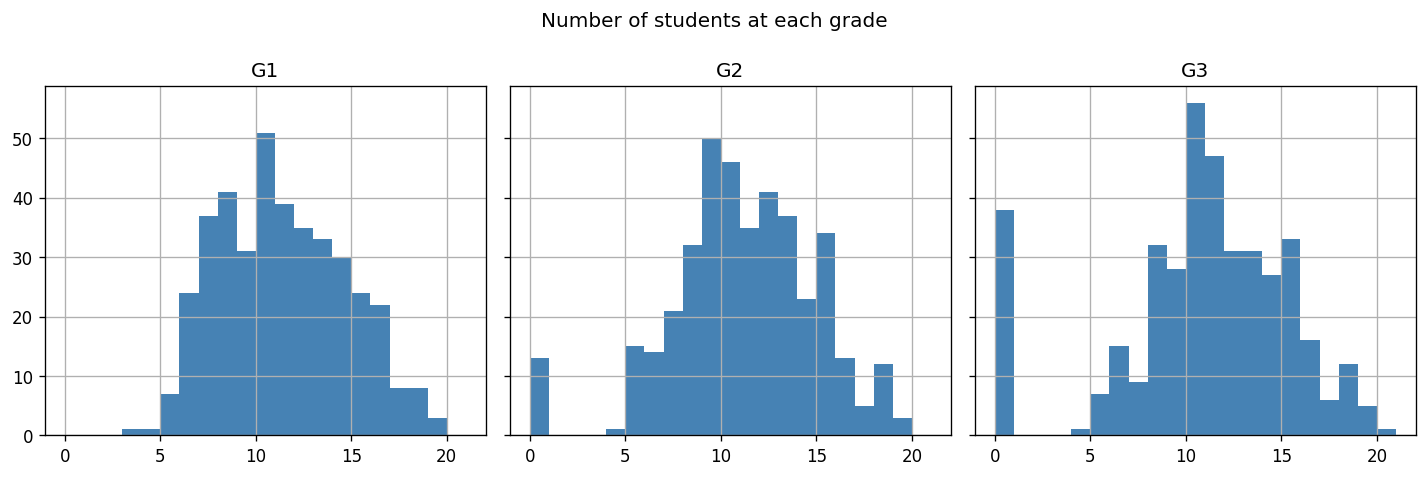

In [12]:
df[["G1", "G2", "G3"]].hist(bins=range(0, 22), layout=(1, 3), figsize=(12, 4),sharex=True, sharey=True, color="steelblue")
plt.suptitle("Number of students at each grade")
plt.tight_layout()
plt.savefig("../images/grade_distributions.png", bbox_inches="tight")
plt.show()

In [13]:
groups = df.groupby("studytime")["G3"]
study = pd.DataFrame()
study["students"] = groups.count()
study["mean_G3"] = groups.mean()
study["median_G3"] = groups.median()

In [14]:
study["sd_G3"] = groups.std()
study["min_G3"] = groups.min()
study["max_G3"] = groups.max()
study["share_pct"] = study["students"] / len(df) * 100
study.index = ["<2 hours", "2–5 hours", "5–10 hours", ">10 hours"]
study.index.name = "study_group"
study

,students,mean_G3,median_G3,sd_G3,min_G3,max_G3,share_pct
study_group,,,,,,,
<2 hours,105,10.047619,10.0,4.956311,0,19,26.582278
2–5 hours,198,10.171717,11.0,4.217537,0,19,50.126582
5–10 hours,65,11.400000,12.0,4.639504,0,19,16.455696
>10 hours,27,11.259259,12.0,5.281263,0,20,6.835443


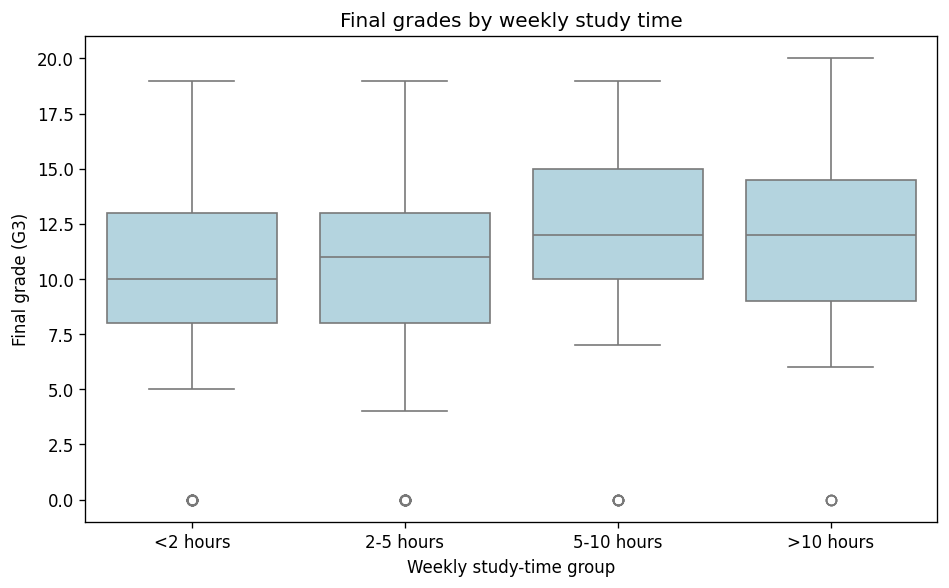

In [15]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3", color="lightblue")
plt.xticks([0, 1, 2, 3], ["<2 hours", "2-5 hours", "5-10 hours", ">10 hours"])
plt.title("Final grades by weekly study time")
plt.xlabel("Weekly study-time group")
plt.ylabel("Final grade (G3)")
plt.ylim(-1, 21)
plt.tight_layout()
plt.savefig("../images/studytime_final_grades.png", bbox_inches="tight")
plt.show()

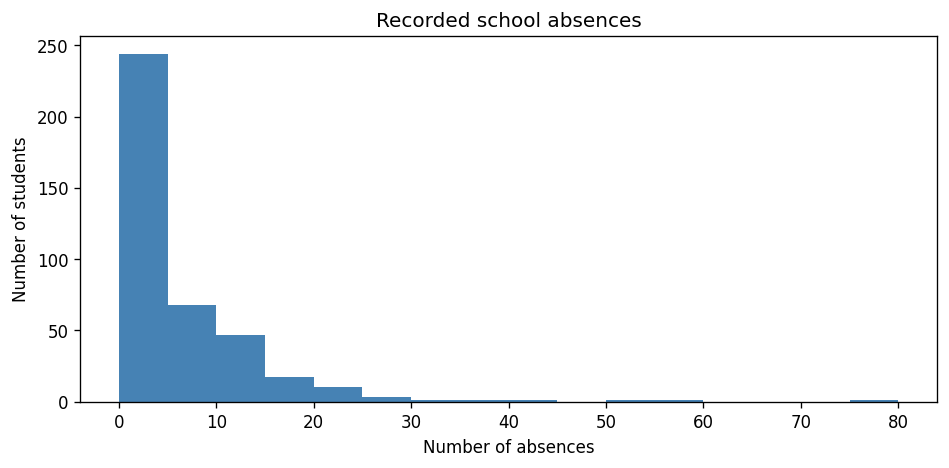

In [16]:
plt.figure(figsize=(8, 4))
plt.hist(df["absences"], bins=range(0, 81, 5), color="steelblue")
plt.title("Recorded school absences")
plt.xlabel("Number of absences")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig("../images/absence_distribution.png", bbox_inches="tight")
plt.show()

In [17]:
pearson = df["absences"].corr(df["G3"])
spearman = df["absences"].corr(df["G3"], method="spearman")
print("Pearson:", pearson)
print("Spearman:", spearman)

Pearson: 0.03424731615006931
Spearman: 0.017730669122425113


In [18]:
zeros = pd.DataFrame()
zeros["zero_grade_count"] = (df[["G1", "G2", "G3"]] == 0).sum()
zeros.index.name = "assessment"
zeros

,zero_grade_count
assessment,
G1,0
G2,13
G3,38


In [19]:
zero = df[df["G3"] == 0]
len(zero)

38

In [20]:
zero["absences"].value_counts()

absences
0    38
Name: count, dtype: int64

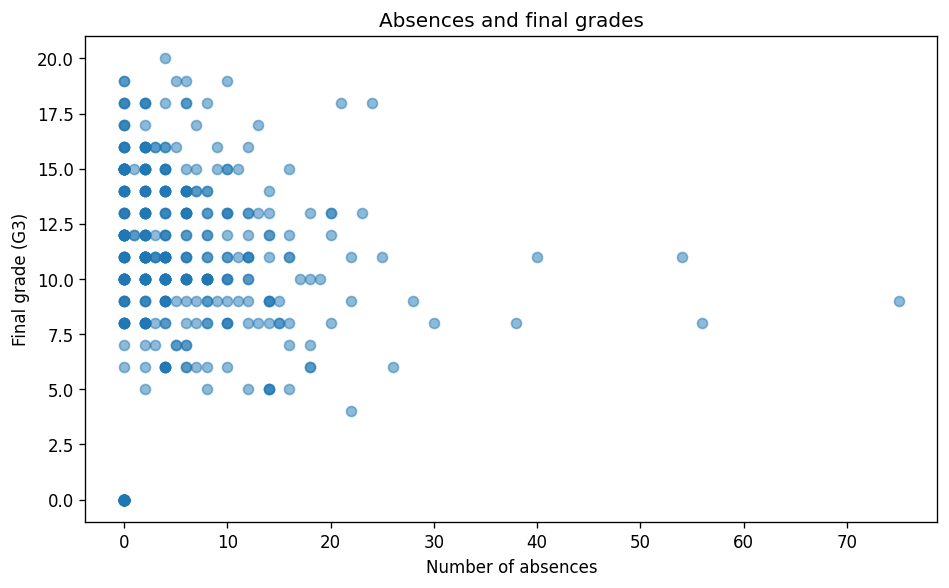

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(df["absences"], df["G3"], alpha=0.5)
plt.title("Absences and final grades")
plt.xlabel("Number of absences")
plt.ylabel("Final grade (G3)")
plt.ylim(-1, 21)
plt.tight_layout()
plt.savefig("../images/absences_final_grades.png", bbox_inches="tight")
plt.show()

In [22]:
positive = df[df["G3"] > 0]
len(positive)

357

In [23]:
pearson_positive = positive["absences"].corr(positive["G3"])
spearman_positive = positive["absences"].corr(positive["G3"], method="spearman")
print("Pearson:", pearson_positive)
print("Spearman:", spearman_positive)

Pearson: -0.21312853214380864
Spearman: -0.244196948637836


In [24]:
correlations = pd.DataFrame()
correlations["sample"] = ["All records (primary)", "G3 > 0 (sensitivity only)"]
correlations["students"] = [len(df), len(positive)]
correlations["pearson_r"] = [pearson, pearson_positive]
correlations["spearman_rho"] = [spearman, spearman_positive]
correlations

,sample,students,pearson_r,spearman_rho
0,All records (primary),395,0.034247,0.017731
1,G3 > 0 (sensitivity only),357,-0.213129,-0.244197


In [25]:
grades = df[["G1", "G2", "G3"]]
grade_summary = pd.DataFrame()
grade_summary["count"] = grades.count()
grade_summary["mean"] = grades.mean()
grade_summary["median"] = grades.median()

In [26]:
grade_summary["std"] = grades.std()
grade_summary["min"] = grades.min()
grade_summary["max"] = grades.max()
grade_summary.index.name = "assessment"
grade_summary

,count,mean,median,std,min,max
assessment,,,,,,
G1,395,10.908861,11.0,3.319195,3,19
G2,395,10.713924,11.0,3.761505,0,19
G3,395,10.415190,11.0,4.581443,0,20


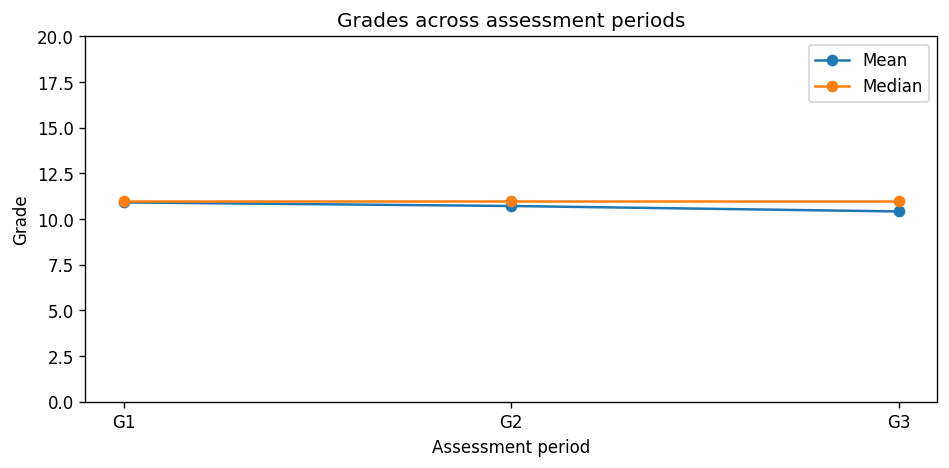

In [27]:
plt.figure(figsize=(8, 4))
plt.plot(grade_summary.index, grade_summary["mean"], marker="o", label="Mean")
plt.plot(grade_summary.index, grade_summary["median"], marker="o", label="Median")
plt.title("Grades across assessment periods")
plt.xlabel("Assessment period")
plt.ylabel("Grade")
plt.ylim(0, 20)
plt.legend()
plt.tight_layout()
plt.savefig("../images/grade_period_trend.png", bbox_inches="tight")
plt.show()

In [28]:
changes = pd.DataFrame()
changes["G1_to_G2"] = df["G2"] - df["G1"]
changes["G2_to_G3"] = df["G3"] - df["G2"]
changes["G1_to_G3"] = df["G3"] - df["G1"]
changes.head()

,G1_to_G2,G2_to_G3,G1_to_G3
0,1,0,1
1,0,1,1
2,1,2,3
3,-1,1,0
4,4,0,4


In [29]:
change_summary = pd.DataFrame()
change_summary["students"] = changes.count()
change_summary["mean_change"] = changes.mean()
change_summary["median_change"] = changes.median()
change_summary["min_change"] = changes.min()
change_summary["max_change"] = changes.max()

In [30]:
change_summary["increased"] = (changes > 0).sum()
change_summary["unchanged"] = (changes == 0).sum()
change_summary["decreased"] = (changes < 0).sum()

In [31]:
change_summary["increased_pct"] = change_summary["increased"] / len(df) * 100
change_summary["unchanged_pct"] = change_summary["unchanged"] / len(df) * 100
change_summary["decreased_pct"] = change_summary["decreased"] / len(df) * 100
change_summary.index.name = "comparison"
change_summary

,students,mean_change,median_change,min_change,max_change,increased,unchanged,decreased,increased_pct,unchanged_pct,decreased_pct
comparison,,,,,,,,,,,
G1_to_G2,395,-0.194937,0.0,-12,4,128,117,150,32.405063,29.620253,37.974684
G2_to_G3,395,-0.298734,0.0,-10,3,111,194,90,28.101266,49.113924,22.784810
G1_to_G3,395,-0.493671,0.0,-12,4,143,93,159,36.202532,23.544304,40.253165


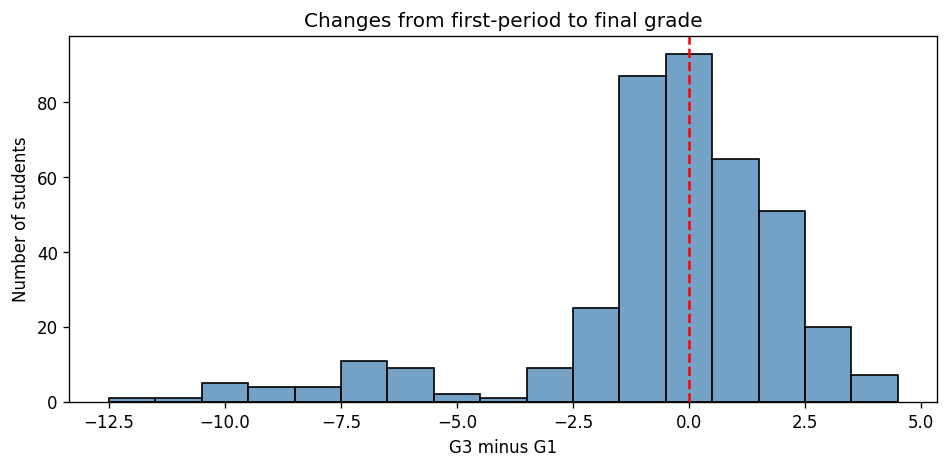

In [32]:
plt.figure(figsize=(8, 4))
sns.histplot(changes["G1_to_G3"], discrete=True, color="steelblue")
plt.axvline(0, color="red", linestyle="--")
plt.title("Changes from first-period to final grade")
plt.xlabel("G3 minus G1")
plt.ylabel("Number of students")
plt.tight_layout()
plt.savefig("../images/grade_change_distribution.png", bbox_inches="tight")
plt.show()

In [33]:
print("Rows:", len(df))
print("Study-group total:", study["students"].sum())

Rows: 395
Study-group total: 395


In [34]:
change_summary[["increased", "unchanged", "decreased"]].sum(axis=1)

comparison
G1_to_G2    395
G2_to_G3    395
G1_to_G3    395
dtype: int64

In [35]:
print("Difference of means:", grades["G3"].mean() - grades["G1"].mean())
print("Mean of differences:", changes["G1_to_G3"].mean())

Difference of means: -0.49367088607594845
Mean of differences: -0.4936708860759494


In [36]:
quality.to_csv("../results/data_quality_checks.csv", index=False)
summary.to_csv("../results/descriptive_statistics.csv", float_format="%.6f")
study.to_csv("../results/studytime_summary.csv", float_format="%.6f")
zeros.to_csv("../results/zero_grade_counts.csv")
correlations.to_csv("../results/absence_correlations.csv", index=False, float_format="%.6f")
grade_summary.to_csv("../results/grade_period_summary.csv", float_format="%.6f")
change_summary.to_csv("../results/grade_change_summary.csv", float_format="%.6f")

## What the results show

- The 5-10-hour study group has the highest observed mean final grade, 11.40. The group sizes differ and the grade distributions overlap.
- Across all 395 records, the absence/final-grade correlations are close to zero. All 38 zero-final-grade records also have zero absences. The smaller-group comparison changes the sample and does not correct the full-sample result.
- Mean grades are 10.91, 10.71 and 10.42 for G1, G2 and G3. The median stays at 11. From G1 to G3, 143 records increase, 93 stay the same and 159 decrease.

These are descriptions of this sample. They do not prove that study time or absences
caused the grade differences. Other factors are not controlled for. The data are historical
and come from two Portuguese schools, so the results cannot be assumed to describe current
students elsewhere. G3 is a related final-year grade; the grade changes do not directly
measure learning gained.

Clarifying how zero grades and absences were recorded would help explain the attendance pattern.

## Source

Cortez, P. (2008). [Student Performance](https://doi.org/10.24432/C5TG7T).
UCI Machine Learning Repository. The dataset is available under
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
The raw CSV and original variable notes are unchanged.
See [DATA_SOURCE.md](../DATA_SOURCE.md) for the data link and field definitions.